In [1]:
# Imports et chargement des données
import pandas as pd
import numpy as np
import random
import tensorflow as tf
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import MinMaxScaler
import joblib
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, LSTM, Bidirectional, Dense, Input, Dropout, GRU
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

# Définir les graines aléatoires pour la reproductibilité
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    
data = pd.read_csv('stock/AAPL.csv', index_col='Date', parse_dates=True)['Close']


data



Date
2013-01-02     16.669012
2013-01-03     16.458618
2013-01-04     16.000164
2013-01-07     15.906051
2013-01-08     15.948846
                 ...    
2022-12-23    130.344498
2022-12-27    128.535492
2022-12-28    124.591385
2022-12-29    128.120331
2022-12-30    128.436661
Name: Close, Length: 2518, dtype: float64

In [2]:
# Prétraitement des données
# Lissage exponentiel
def exponential_smoothing(data, alpha=0.1):
    smoothed_data = [data.iloc[0]]
    for i in range(1, len(data)):
        smoothed_value = alpha * data.iloc[i] + (1 - alpha) * smoothed_data[-1]
        smoothed_data.append(smoothed_value)
    return np.array(smoothed_data)

prices_smoothed = exponential_smoothing(data)

# Normalisation des données
scaler = MinMaxScaler(feature_range=(0, 1))
prices_scaled = scaler.fit_transform(prices_smoothed.reshape(-1, 1))

# Sauvegarder le scaler pour une utilisation future
joblib.dump(scaler, 'scaler_minmax_gru.pkl')

['scaler_minmax_gru.pkl']

In [3]:
#  Création des séquences
# Fonction pour créer les séquences

def create_sequences(data, sequence_length):
    X, y = [], []
    for i in range(len(data) - sequence_length):
        X.append(data[i:i+sequence_length])
        y.append(data[i+sequence_length])
    return np.array(X), np.array(y)

sequence_length = 3
X, y = create_sequences(prices_scaled, sequence_length)

# Diviser les données en ensembles d'entraînement et de test (70% / 30%)
train_size = int(len(X) * 0.7)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"Forme de X_train: {X_train.shape}")
print(f"Forme de y_train: {y_train.shape}")
print(f"Forme de X_test: {X_test.shape}")
print(f"Forme de y_test: {y_test.shape}")

Forme de X_train: (1760, 3, 1)
Forme de y_train: (1760, 1)
Forme de X_test: (755, 3, 1)
Forme de y_test: (755, 1)


In [4]:
#  Définition du modèle

def create_model(input_shape):
    model = Sequential([
        Input(shape=input_shape),
        GRU(units=64, activation='tanh', return_sequences=True),
        Dropout(0.25),
        GRU(units=256, activation='tanh', return_sequences=False),
        Dropout(0.25),
        Dense(units=1)
    ])
    
    model.compile(optimizer=Adam(learning_rate=0.0001), loss='huber', metrics=['mae'])
    return model

In [5]:
#  Entraînement du modèle final
# Créer et compiler le modèle final
set_seed(42)
final_model = create_model(input_shape=(X_train.shape[1], X_train.shape[2]))

# Définir early stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

# Entraîner le modèle sur l'ensemble complet des données d'entraînement
final_history = final_model.fit(
    X_train, y_train,
    batch_size=128,
    epochs=100,
    verbose=1
)



Epoch 1/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - loss: 0.0089 - mae: 0.1072
Epoch 2/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0037 - mae: 0.0652
Epoch 3/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0019 - mae: 0.0512
Epoch 4/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0016 - mae: 0.0491
Epoch 5/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0013 - mae: 0.0436
Epoch 6/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 9.8533e-04 - mae: 0.0378
Epoch 7/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 7.5599e-04 - mae: 0.0331
Epoch 8/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 5.2727e-04 - mae: 0.0277
Epoch 9/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 3.2693e-04 - mae: 0.0212
Epoch 10/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 1.7916e-04 - mae: 0.0157
Epoch 11/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 1.0036e-04 - mae: 0.0109
Epoch 12/100
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 5.7038e-05 - mae: 0.00

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 2.2816e-05 - mae: 0.0054 
Test Loss: 0.0000, Test MAE: 0.0063
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step


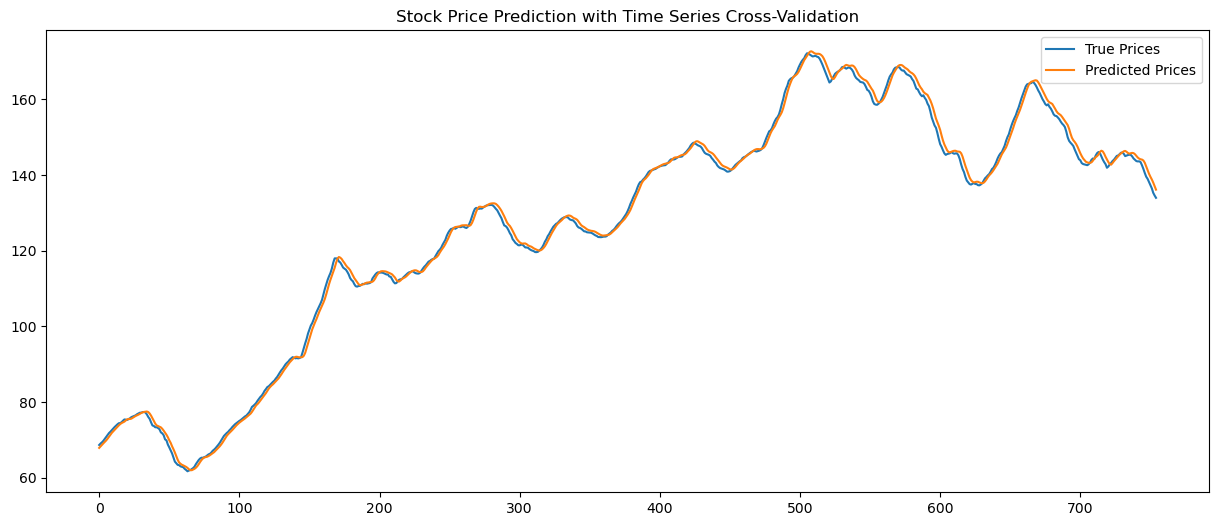

In [6]:
# Évaluation du modèle final
# Évaluer le modèle sur l'ensemble de test
test_loss, test_mae = final_model.evaluate(X_test, y_test)
print(f"Test Loss: {test_loss:.4f}, Test MAE: {test_mae:.4f}")

# Faire des prédictions
y_pred = final_model.predict(X_test)

# Convertir les prix prédits et réels à l'échelle initiale
y_test_unscaled = scaler.inverse_transform(y_test.reshape(-1, 1))
y_pred_unscaled = scaler.inverse_transform(y_pred)

# Tracer les résultats
plt.figure(figsize=(15, 6))
plt.plot(y_test_unscaled, label='True Prices')
plt.plot(y_pred_unscaled, label='Predicted Prices')
plt.title('Stock Price Prediction with Time Series Cross-Validation')
plt.legend()
plt.show()

In [7]:
# Métriques d'évaluation détaillées
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

def calculate_directional_accuracy(y_true, y_pred):
    # Calcul des différences entre les points consécutifs
    y_true_direction = np.diff(y_true.flatten())
    y_pred_direction = np.diff(y_pred.flatten())
    
    # Calcul de la précision directionnelle
    correct_direction = np.sum((y_true_direction * y_pred_direction) > 0)
    return (correct_direction / len(y_true_direction)) * 100

# Calculer les métriques
mse = mean_squared_error(y_test_unscaled, y_pred_unscaled)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_unscaled, y_pred_unscaled)
r2 = r2_score(y_test_unscaled, y_pred_unscaled)
mape = calculate_mape(y_test_unscaled, y_pred_unscaled)
da = calculate_directional_accuracy(y_test_unscaled, y_pred_unscaled)

# Afficher les métriques
print("Métriques d'évaluation:")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R²: {r2:.4f}")
print(f"MAPE: {mape:.2f}%")
print(f"Directional Accuracy: {da:.2f}%")

Métriques d'évaluation:
MSE: 1.5729
RMSE: 1.2542
MAE: 1.0099
R²: 0.9983
MAPE: 0.82%
Directional Accuracy: 85.01%


In [8]:
#Sauvegarder le modèle final
final_model.save('model_gru.keras')
print("Modèle sauvegardé avec succès!")

Modèle sauvegardé avec succès!
